<a href="https://colab.research.google.com/github/felipe-suarez06/Explorando-drivers-de-comportamiento-en-NovaRetail-/blob/main/Proyecto_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

In [ ]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`


La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` esta presente como float pero conceptualmente es una variable discreta entera (int)
se sugiere convertirla a (int) si se desea limpiar el dataset.

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:
# Corregir el tipo de dato
df["edad"] = df["edad"].astype(int)

In [ ]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


Diagnóstico inicial de variables numéricas
Se analizó la distribución de cada variable con .describe() y se observó que:

- `edad` — distribución simétrica, media y mediana pegadas, variación mínima explicada por pocos casos cercanos al máximo de 75 años.
- `nivel_ingreso` - distribución simétrica, media y mediana pegadas, variación mínima explicada por algunos casos cercanos al máximo de 74790.84 , a pesar de que el máximo parezca una cantidad grande, no está tan alejado como para causar un sesgo  real, solo es el valor más alto dentro de un rango razonable.
- `visitas_mes` -  la distribución es mayormente simétrica, pero hay posibles outliers en el extremo superior que merecen atención. Esto se explica al comparar el percentil 75%  que es de 12 visitas y el máximo que es de 25 visitas, más del doble.
- `compras_mes`- la distribución es asimétrica y sesgada a la derecha, se aprecia una media estirada acia arriba en comparacion con la mediana, aunque pareciera una cantidad minima la diferencia de 0.206 es grande referente a la proporcion con el 1 que equibale a la mediana, explicado por valores atipicos a la derecha donde al comparar el valor del percentil 75% que es de 2 compras y el maximo que aparece de 8, claramente se obserba que es cuatro veces mayor este máximo,
- `gasto_publicidad_dirigida`- distribución mayormente simétrica, media y mediana pegadas, con posibles outliers en el extremo derecho dado que el máximo (75.51) duplica el percentil 75 (27.29).
- `satisfacción`- distribución simétrica (media y mediana prácticamente iguales) y sin indicios de outliers, ya que el máximo (5.0) está cerca del percentil 75 (4.1), una diferencia razonable y no desproporcionada como en los casos anteriores.
- `ingreso_anual`la distribución es asimétrica, sesgada a la derecha, se aprecia una media estirada hacia arriba en comparación con la mediana, explicado por valores atípicos a la derecha donde al comparar el maximo (244.69) con el valor del percentil 75 (58.22), se puede observar que es 4 veces más

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
df[["miembro_premium","abandono"]].nunique()

miembro_premium    2
abandono           2
dtype: int64

Diagnóstico inicial de variables binarias

Se analizó la distribución de cada variable con .describe() y se observó que:
Mirando la media de cada una (que en variables binarias representa justamente la proporción de 1s):
-`miembro_premium` media = 0.139 o 13.9 % de 1s, indicando que son muy pocos los miembros premium.
-`abandono` media = 0.151 o 15.1% de 1s, aunque son pocos los que abandonan, es una proporción que vale la pena tener en cuenta, ya que implica una perdida de clientes.

Haciendo uso del método .nunique() se verifica que cada columna tiene solo dos valores posibles
miembro_premium    2
abandono           2
dtype: int64

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
df[["tipo_dispositivo","region"]].nunique()

tipo_dispositivo    3
region              4
dtype: int64

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
#print(df[["tipo_dispositivo","region"]].apply(lambda col: col.value_counts()))

print(df["tipo_dispositivo"].value_counts())
print()
print(df["tipo_dispositivo"].value_counts(normalize=True))
print()
print(df["region"].value_counts())
print()
print(df["region"].value_counts(normalize=True))

móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

móvil         0.654533
escritorio    0.248000
tablet        0.097467
Name: tipo_dispositivo, dtype: float64

norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64

norte    0.2930
oeste    0.2540
sur      0.2484
este     0.2046
Name: region, dtype: float64


Diagnóstico inicial de variables categóricas

aplicando .nunique() podemos ver que:
- `tipo_dispositivo` — tiene 3 valores únicos (escritorio, móvil,tablet)
-`region` - tiene 4 valores únicos (este, norte, oeste, sur)

Aplicando value_counts() podemos ver cuántas veces aparece cada valor:
-`tipo_dispositivo` — (escritorio(3720.0), móvil(9818.0),tablet(1462.0))
-`region` - (este(3069.0), norte(4395.0), oeste(3810.0), sur(3726.0))

aplicando .value_counts(normalize=True) podemos darnos cuenta de:
Móvil predomina con ≈65% y tablet es minoría ≈10%
Las regiones están relativamente equilibradas, con el norte en ≈29%, siendo el mayor, y el este el menor con ≈20%.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

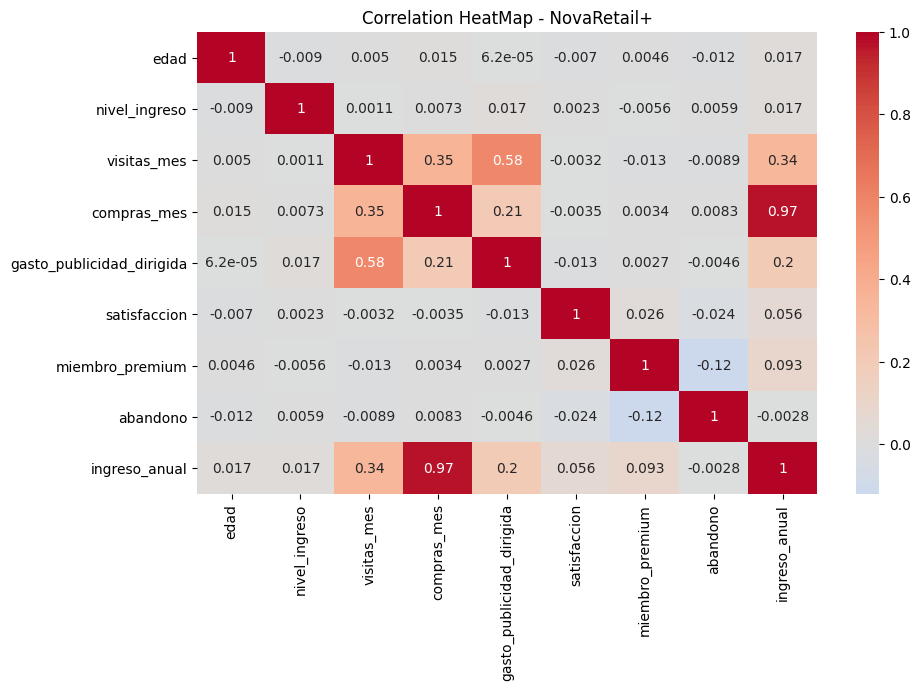


la versión de pandas es:
1.2.4


In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
df_numerico = df.select_dtypes(include="number")
corr = df_numerico.corr()
plt.figure(figsize=(10,6))
sns.heatmap(corr, annot= True, cmap= "coolwarm", center=0)
plt.title("Correlation HeatMap - NovaRetail+")
plt.show()
print()
print("la versión de pandas es:")
print(pd.__version__)

Observaciones generales (Heatmap)  
- Se observa que hay variables que presentan una correlación fuerte, por ejemplo, ingreso_anual y compras_mes con 0.97, aunque aquí habría que analizarlo más a fondo ya que podría ser una colinealidad.
  
- Otras variables presentan una correlación moderada-fuerte, estas son:
  -gasto_publicidad_dirigida  y visitas_mes se correlacionan positivamente.

  
- Otras variables presentan una correlación moderada, estas son:
  -compras_mes y visitas_mes, se correlacionan positivamente.
  -ingreso_anual y visitas_mes, se correlacionan positivamente.

  
- Otras variables presentan una correlación débil, estas son:
  -gasto_publicidad_dirigida  y compras_mes, se correlacionan positivamente.
  -ingreso_anual y gasto_publicidad_dirigida,se correlacionan positivamente.

-La mayoría de las correlaciones son nulas o cercanas a cero.

Observaciones respecto a `ingreso_anual`  
- Presenta una mayoría de correlaciones nulas o cercanas a cero, tanto positivas como negativas.
- La variable con la que tiene una correlación fuerte es: compras_mes,
- correlación débil con: visitas_mes y gasto_publicidad_dirigida


### Scatterplot general

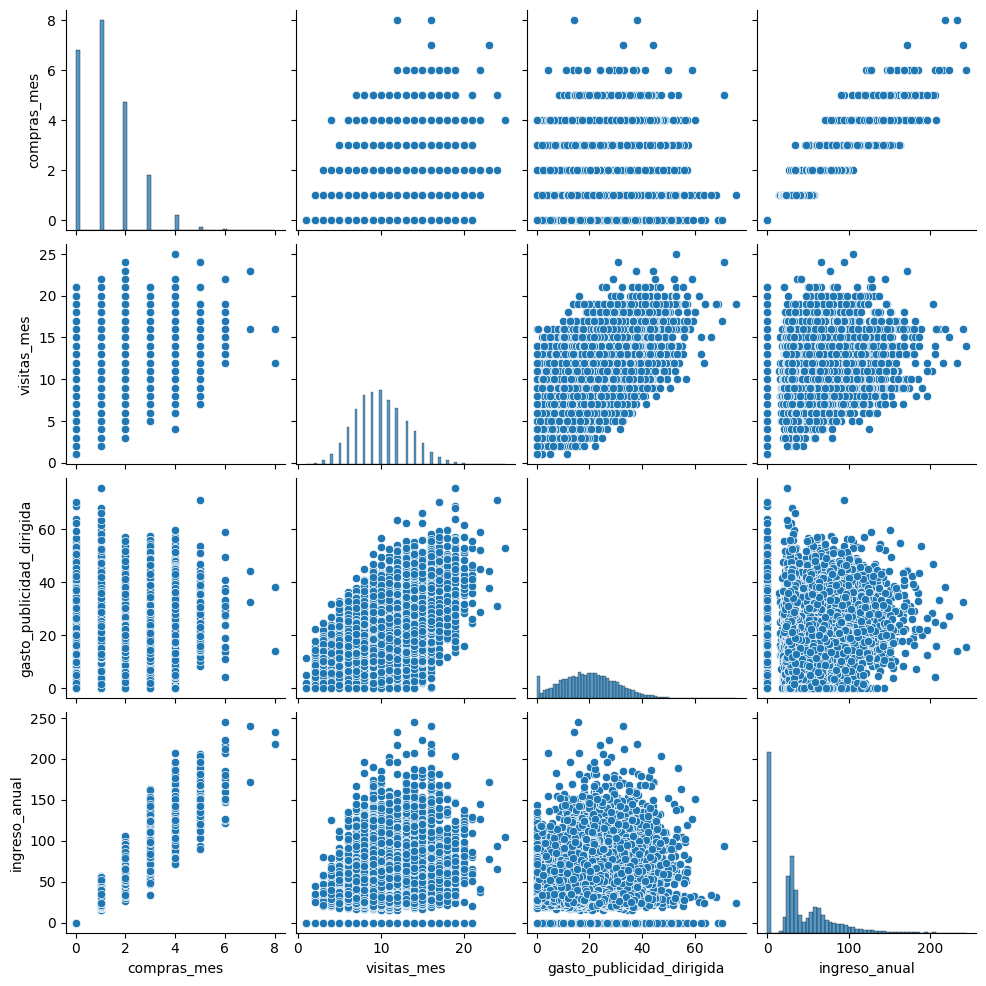

In [ ]:
sns.pairplot(df[['compras_mes','visitas_mes','gasto_publicidad_dirigida','ingreso_anual']])

Describe brevemente qué patrones o tendencias observas.
Ingreso_anual y compra_mes: muestran una tendencia ascendente clara, con los puntos agrupados cerca de una línea, lo que indica una relación fuerte. Por otro lado gasto_publicidad_dirigida y visitas_mes, muestran una tendencia ascendente , con los puntos agrupados cerca de una línea, ligeramente dispersos, lo que indica una relación moderada-fuerte. Asimismo, (compra_mes y visitas_mes) y (ingreso_anual y visitas_mes) muestran una tendencia ascendente, con los puntos más alejados de una línea, lo que indica una relación moderada. En cambio, (gasto_publicidad_dirigida y compra_mes) y (ingreso_anual y gasto_publicidad_dirigida) muestran una tendencia ascendente, con una dispersión más grande, lo que indica una relación débil.

### Scatterplot para pares clave

<AxesSubplot:xlabel='compras_mes', ylabel='ingreso_anual'>

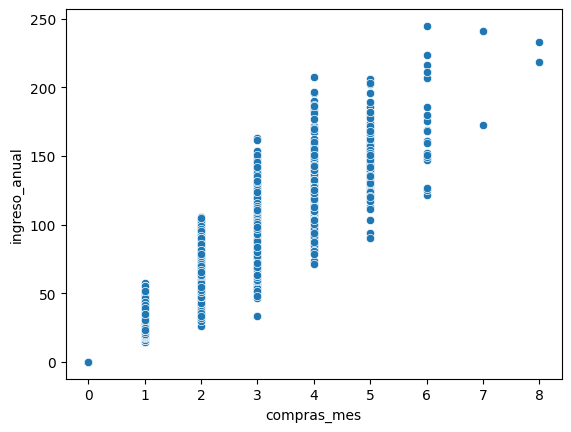

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes
sns.scatterplot(data=df, x='compras_mes', y='ingreso_anual')

<AxesSubplot:xlabel='visitas_mes', ylabel='gasto_publicidad_dirigida'>

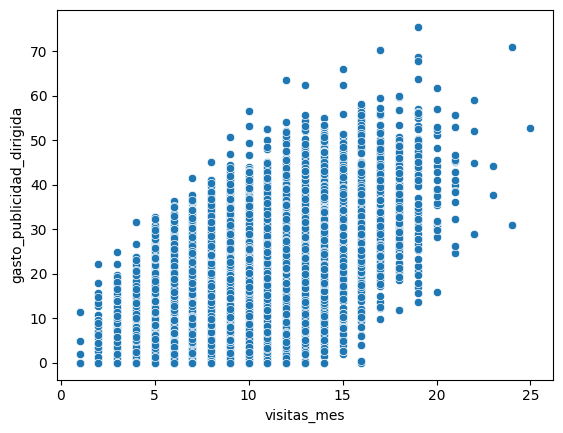

In [ ]:
sns.scatterplot(data= df, x="visitas_mes", y = "gasto_publicidad_dirigida")

Observaciones iniciales (Scatterplot)


'ingreso_anual'vs'compras_mes'
- Dirección positiva
- dispersión baja
- presencia de outliers
- colinealidad.

"visitas_mes" vs "gasto_publicidad_dirigida"
- Dirección positiva
- Dispersión moderada
- presencia de outliers
- colinealidad moderada.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
print(df['ingreso_anual'].corr(df['compras_mes'], method='pearson'))
df['ingreso_anual'].corr(df['compras_mes'], method='spearman')

0.9671485435708566


0.9674824920326731

In [ ]:
# Calcular correlación entre variables relevantes
print(df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='pearson'))
df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='spearman')

0.5789472719412827


0.5592673242622609

Observaciones de correlación


'ingreso_anual'vs'compras_mes'
- Correlación positiva
- Magnitud alta
- colinealidad alta.
- la relación es lineal y monótona, y los valores extremos no la distorsionan.

"visitas_mes" vs "gasto_publicidad_dirigida"
- Correlación positiva
- Magnitud moderada
- colinealidad moderada
- la relación es medianamente lineal y monótona, y los valores extremos no la distorsionan.

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr
print("pointbiserialr: miembro_premium vs ingreso_anual")
print(pointbiserialr(df["miembro_premium"],df["ingreso_anual"]))
print()
print("pointbiserialr: abandono vs ingreso_anual")
print(pointbiserialr(df["abandono"],df["ingreso_anual"]))
print()
print("pointbiserialr: abandono vs satisfaccion")
pointbiserialr(df["abandono"],df["satisfaccion"])

pointbiserialr: miembro_premium vs ingreso_anual
SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)

pointbiserialr: abandono vs ingreso_anual
SignificanceResult(statistic=-0.002823934021617148, pvalue=0.7294691719078393)

pointbiserialr: abandono vs satisfaccion


SignificanceResult(statistic=-0.02383256067380403, pvalue=0.003510976893362289)

Observaciones Punto-biserial


"miembro_premium" vs "ingreso_anual"
- dirección positiva
- magnitud baja
  
El p-value es extremadamente pequeño, relación, aunque débil, es estadísticamente significativa.


"abandono" vs "ingreso_anual"
- dirección negativa
- magnitud baja (prácticamente nula)
  
El p-value (0.729) es muy alto, mucho mayor que 0.05, lo que significa que esta relación no es estadísticamente significativa. Es decir, que no hay evidencia de que exista relación real entre esas variables (podría deberse al azar).


"abandono" vs "satisfacción"
- dirección negativa
- magnitud baja (prácticamente nula)
  
El p-value es pequeño; la relación, aunque débil, es estadísticamente significativa.

### V de Cramér

In [ ]:

# Función para calcular V de Cramér
from scipy.stats import chi2_contingency

def v_cramers(df, col_1, col_2):
    #creando tabla de contingencia
    tabla= pd.crosstab(df[col_1], df[col_2])
    #calculando chi2
    chi2,_,_,_ = chi2_contingency(tabla)
    #calculando coeficiente v de cramers
    n = tabla.sum().sum()
    v= np.sqrt(chi2/(n*(min(tabla.shape)-1)))
    return v



In [ ]:
# Aplicar V de Cramér en variables relevantes
cramers_v = v_cramers(df,"tipo_dispositivo","region")
cramers_v

0.012378338407739397

In [ ]:
# Aplicar V de Cramér en variables relevantes
cramers_v = v_cramers(df,"miembro_premium","abandono")
cramers_v

0.12021874609740511

Observaciones V de Cramér:("tipo_dispositivo" vs "region")

El resultado es un valor cercano a cero, lo que indica que la asociación entre tipo_dispositivo y región es muy débil.
En otras palabras, el dispositivo que usan los usuarios no varía de forma relevante según la región.

Observaciones V de Cramér:("miembro_premium" vs "abandono")
El valor es ≈ 0.12 lo que indica una asociación débil, es decir, que los premium abandonan menos.

## Sección 5 - Interpretación de resultados para el negocio
---

### Hallazgo 1 — correlación entre compras_mes e ingreso_anual

**Evidencia visual:**
El scatterplot muestra una clara tendencia ascendente  entre compras_mes e ingreso_anual.

**Evidencia numérica:**
La correlación de Pearson es de 0.967

**Interpretación**  
A mayor compras_mes, mayor ingreso_anual.

**No podemos afirmar**  
No se puede asumir que ambas aportan información independiente,es difícil saber cuál de las dos es la que realmente impulsa el comportamiento observado, debido a que las variables están tan correlacionadas, son casi redundantes entre sí a nivel estadístico.

**Implicación de negocio**
Dado que no se puede determinar qué variable impulsa a la otra, se puede usar compras_mes como indicador temprano para detectar clientes de alto valor y dirigirles campañas de fidelización que incentiven mantener esa frecuencia de compra, ya que está asociada a un mayor ingreso generado por el cliente


### Hallazgo 2 — visitas_mes y gasto_publicidad_dirigida

**Evidencia visual:**
El scatterplot muestra una dispersión moderada y una tendencia ascendente entre visitas_mes y gasto_publicidad_dirigida.

**Evidencia numérica:**
La correlación de Pearson es de 0.5789

**Interpretación**  
La relacion entre publicidad dirigida y visitas mes, es moderada, no fuerte, generando una variabilidad considerable que esta variable no puede explicar

**No podemos afirmar**  
No podemos afirmar que invirtiendo más en la publicidad dirigida genere más visitas por mes, ya que podría haber otros factores como a qué grupo va dirigido la publicidad

**Implicación de negocio**  
Tomando en cuenta la correlación moderada entre publicidad dirigida y visitas mes, complementaria esta estrategia con otro medio de contacto para incentivar a los clientes a visitar la tienda


## Hallazgo 3 — tipo_dispositivo y región

**Evidencia visual:**
 "El heatmap muestra que la distribución de tipo_dispositivo es similar en todas las regiones, sin picos o concentraciones marcadas en ninguna combinación específica."
**Evidencia numérica:**
La correlación de V de Cramer es de 0.012378

**Interpretación**  
El resultado es un valor cercano a cero, lo que indica que la asociación entre tipo_dispositivo y región es muy débil.

**No podemos afirmar**  
No podemos afirmar que el dispositivo que usan los usuarios varíe según la región.

**Implicación de negocio**
Al no haber un patrón que justifique estrategias distintas por región, seria mejor enfocarse en una estrategia generalizada


tipo_dispositivo  escritorio  móvil  tablet
region                                     
este                     766   2003     300
norte                   1125   2843     427
oeste                    935   2489     386
sur                      894   2483     349


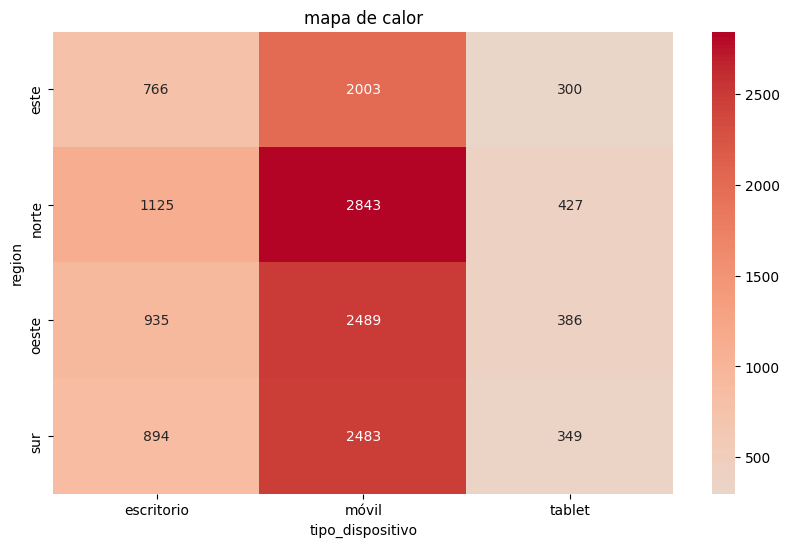

In [ ]:
#heatmap de region vs tipo_dispositivo

tabla = pd.crosstab(df["region"],df["tipo_dispositivo"])
print(tabla)
plt.figure(figsize=(10,6))
sns.heatmap(tabla, annot = True, cmap= "coolwarm", center=0, fmt="d")
plt.title("mapa de calor")
plt.show()


## Hallazgo 4 — ingreso_anual y visitas_mes

**Evidencia visual:**  
En el scatterplot general podemos ver una dispersión moderada y una tendencia ascendente entre visitas_mes e ingreso_anual.

**Evidencia numérica:**
La correlación de pearson es 0.337

**Interpretación**  
La relación entre visitas_mes e ingreso_anual, es débil, generando una variabilidad muy grande que esta variable no puede explicar.

**No podemos afirmar**  
No podemos afirmar que el ingreso _anual de los usuarios sea generado por una mayor cantidad de visitas de la tienda, ya que podría haber otros factores como compras_mes

**Implicación de negocio**
Tomando en cuenta la correlación débil entre ingreso_anual y visitas_mes, complementaria esta estrategia con otra variable por ejemplo compras_mes


In [ ]:
# Calcular correlación entre variables
df['visitas_mes'].corr(df['ingreso_anual'], method='pearson')

0.3371466432498745

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- Correlación ≠ causalidad
- la relación entre dos variables fuera fuerte pero no lineal, el método usado pearson podría no detectar relaciones reales si estas no son lineales
- los datos son de un solo año
- la relación compras↔ingreso es casi mecánica.

### **Próximos pasos**

Probar segmentación adicional
- Segmentar los clientes, combinando edad e ingreso_anual para identificar los perfiles de más alto valor.

Profundizar en relaciones entre variables
- analizar compras_mes como mediador entre visitas_mes e ingreso_anual.

modelado predictivo
- Desarrollar un modelo predictivo que use ingreso_anual y compras_mes para predecir la probabilidad de ser miembro premium.